# Clase — Aprendizaje supervisado: flujo completo con árboles de decisión

**Bases de Datos Masivas (11088) — 2026**

Esta notebook recorre, de punta a punta, el flujo de trabajo de un problema de
**clasificación**: desde el muestreo hasta la evaluación final, pasando por el ajuste de
hiperparámetros con validación cruzada.

**Flujo:**

```
datos ──► split train / test ──► (sobre train) CV para elegir modelo e hiperparámetros ──► test UNA vez
```

El conjunto de test se aparta al principio y no se toca hasta el final. Todo lo
que decidamos antes (qué modelo, qué profundidad, qué umbral) se decide mirando sólo train.

## 0. Librerías y configuración

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, ShuffleSplit, KFold, StratifiedKFold,
                                     LeaveOneOut, cross_val_score, cross_validate,
                                     cross_val_predict, validation_curve, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             fbeta_score, cohen_kappa_score, roc_auc_score, make_scorer,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve)

warnings.filterwarnings("ignore", category=FutureWarning)

SEMILLA = 2026

pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

import sklearn
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.0 | pandas 3.0.5


### Los datos: abandono en la UNLu

`abandono_cuantitativo.csv` (en `jupyterlab/data/`) tiene una fila por alumno ingresante de la UNLu, con datos
sociodemográficos (edad, si trabaja, tipo de colegio, beca Progresar…) y su desempeño en el
primer año (materias cursadas, promocionadas, regularizadas, libres, ausentes).

La variable objetivo es **`fracaso_academico`** (1 = fracasó en el primer año). Es el mismo
archivo del TP04, que allá se usa sin la etiqueta, para clustering.

In [2]:
datos = pd.read_csv("../data/abandono_cuantitativo.csv", sep=";")
OBJETIVO = "fracaso_academico"

print("Dimensiones:", datos.shape)
datos.head()

Dimensiones: (16334, 21)


,horas_trabajadas,masculino,edad_ingreso,colegio_publico,argentino,activo_primer_anio,activo_segundo_anio,anios_en_unlu,aprobadas_1er_anio,anios_cursados,c_promociones_1er_anio,c_libres_1er_anio,c_regulares_1er_anio,c_ausentes_1er_anio,c_noausentes_1er_anio,cursadas_ap_1er_anio,cursadas_1er_anio,cambio_universidad,cambio_carrera,progresar,fracaso_academico
0,0,0,22,1,1,1,0,1.0,0,1,0,3,4,8,8,4,16,0,1,0,0
1,0,0,21,1,1,0,1,2.0,0,2,0,0,1,3,1,1,4,0,0,1,0
2,0,0,54,1,1,1,0,3.0,0,3,0,0,0,2,0,0,2,0,1,0,0
3,0,0,28,1,1,1,0,3.0,0,3,0,0,0,2,0,0,2,0,0,0,0
4,24,0,28,1,1,1,1,2.0,0,2,0,0,1,0,1,1,1,0,0,0,0


In [3]:
datos.isna().sum().loc[lambda s: s > 0]

anios_en_unlu    8
dtype: int64

Hay 8 valores faltantes en `anios_en_unlu`. No los vamos a imputar "a mano" sobre todo el
dataset: lo hace un `SimpleImputer` **dentro del pipeline** de cada modelo, para que la
mediana se calcule sólo con los datos de entrenamiento de cada fold (si no, el test
"filtraría" información al entrenamiento).

### La variable objetivo

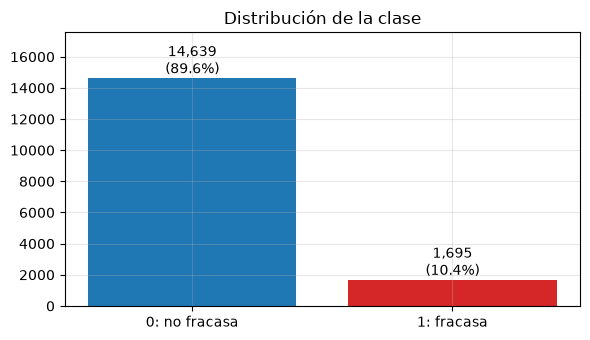

In [4]:
conteo = datos[OBJETIVO].value_counts().sort_index()
prop = datos[OBJETIVO].value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["0: no fracasa", "1: fracasa"], conteo.values, color=["tab:blue", "tab:red"])
for i, (n, p) in enumerate(zip(conteo, prop)):
    ax.text(i, n, f"{n:,}\n({p:.1%})", ha="center", va="bottom")
ax.set_ylim(0, conteo.max() * 1.2)
ax.set_title("Distribución de la clase")
plt.tight_layout()
plt.show()

La clase está **desbalanceada**: sólo uno de cada diez alumnos es positivo. Esto va a
condicionar todo lo que sigue, en particular qué métrica tiene sentido mirar.

### 0.1 Antes de modelar: ¿cómo se construyó la etiqueta?

Miremos la correlación de cada variable con el objetivo:

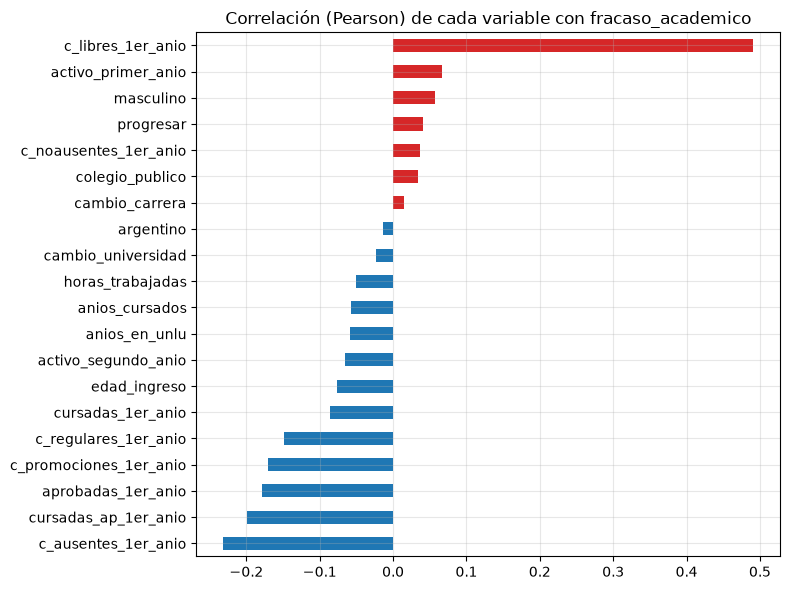

In [5]:
corr = datos.corr()[OBJETIVO].drop(OBJETIVO).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
corr.plot.barh(ax=ax, color=np.where(corr > 0, "tab:red", "tab:blue"))
ax.set_title("Correlación (Pearson) de cada variable con fracaso_academico")
plt.tight_layout()
plt.show()

`c_libres_1er_anio` se despega del resto. Cuando una variable sobresale tanto, hay que
sospechar: **¿la etiqueta no estará calculada a partir de ella?** Probemos la hipótesis más
natural: "fracasa quien quedó libre en más de la mitad de las materias que cursó".

In [6]:
proporcion_libres = datos.c_libres_1er_anio / datos.cursadas_1er_anio.replace(0, np.nan)
regla = (proporcion_libres > 0.5).astype(int)

print(f"La regla coincide con la etiqueta en el {(regla == datos[OBJETIVO]).mean():.2%} de los casos")
pd.crosstab(pd.cut(proporcion_libres, [-0.01, 0.2, 0.4, 0.5, 0.6, 0.8, 1]), datos[OBJETIVO])

La regla coincide con la etiqueta en el 100.00% de los casos


fracaso_academico,0,1
row_0,,
"(-0.01, 0.2]",8709,0
"(0.2, 0.4]",3869,0
"(0.4, 0.5]",1468,0
"(0.5, 0.6]",0,461
"(0.6, 0.8]",0,799
"(0.8, 1.0]",0,435


**Exactamente el 100 %.** La etiqueta no es algo que haya que *aprender*: es una fórmula
sobre dos columnas del propio dataset. Si dejamos esas columnas, cualquier modelo va a dar
F1 ≈ 1 y vamos a creer que hicimos un modelo excelente, cuando lo único que hizo fue
redescubrir la fórmula.

Esto se llama **fuga de información** (*data leakage*): entre los predictores hay
información que, en el momento en que se quiere usar el modelo, no estaría disponible, o
que directamente *es* la respuesta. Es el error más común y más caro en ML, y no lo detecta
ninguna métrica: sólo se detecta **entendiendo cómo se generaron los datos**.

Para tener un problema genuino, nos planteamos esta pregunta: *¿podemos anticipar el fracaso
sin saber cuántas materias quedaron libres?* Para eso sacamos:

- `c_libres_1er_anio` y `cursadas_1er_anio`: las dos variables de la fórmula.
- `c_noausentes_1er_anio`: es exactamente `cursadas_1er_anio − c_ausentes_1er_anio`, así
  que con ella (y las ausentes) se reconstruye `cursadas_1er_anio`.

In [7]:
print("c_noausentes == cursadas − ausentes:",
      (datos.c_noausentes_1er_anio == datos.cursadas_1er_anio - datos.c_ausentes_1er_anio).mean())

FUGA = ["c_libres_1er_anio", "cursadas_1er_anio", "c_noausentes_1er_anio"]

X = datos.drop(columns=[OBJETIVO] + FUGA)
y = datos[OBJETIVO]
VARIABLES = X.columns.tolist()

print(f"\n{len(VARIABLES)} variables predictoras:", VARIABLES)

c_noausentes == cursadas − ausentes: 1.0

17 variables predictoras: ['horas_trabajadas', 'masculino', 'edad_ingreso', 'colegio_publico', 'argentino', 'activo_primer_anio', 'activo_segundo_anio', 'anios_en_unlu', 'aprobadas_1er_anio', 'anios_cursados', 'c_promociones_1er_anio', 'c_regulares_1er_anio', 'c_ausentes_1er_anio', 'cursadas_ap_1er_anio', 'cambio_universidad', 'cambio_carrera', 'progresar']


---

## 1. Muestreo

El objetivo de un modelo no es clasificar bien los datos con los que se entrenó, sino los
datos **que todavía no vio**. Para estimar cómo le va a ir con datos nuevos, separamos una
parte de los datos que el modelo nunca ve durante el entrenamiento.

### 1.1 Hold-out: train y test

`train_test_split` asigna cada fila al azar a uno de los dos conjuntos. Con una clase
desbalanceada conviene **estratificar** (`stratify=y`): así los dos conjuntos tienen la misma
proporción de positivos que el total. Veamos qué pasa con y sin estratificar, para distintas
semillas:

In [8]:
filas = []
for semilla in range(10):
    for estratificar in [False, True]:
        _, _, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=semilla,
                                          stratify=y if estratificar else None)
        filas.append({"semilla": semilla, "estratificado": estratificar,
                      "% positivos train": ytr.mean() * 100, "% positivos test": yte.mean() * 100})

(pd.DataFrame(filas)
   .pivot(index="semilla", columns="estratificado", values="% positivos test")
   .rename(columns={False: "sin estratificar", True: "estratificado"})
   .describe().loc[["mean", "std", "min", "max"]])

estratificado,sin estratificar,estratificado
mean,10.459,10.376
std,0.376,0.000
min,9.734,10.376
max,11.081,10.376


Sin estratificar, la proporción de positivos en test se mueve según la semilla. Con
16 mil filas la diferencia es chica, pero con datasets más chicos o clases más raras puede
ser grande. Estratificado, queda clavada.

Este es **el split definitivo** de la notebook: 80 % train, 20 % test.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

print(f"train: {len(X_train):,} filas ({y_train.mean():.1%} positivos)")
print(f"test : {len(X_test):,} filas ({y_test.mean():.1%} positivos)")

train: 13,067 filas (10.4% positivos)
test : 3,267 filas (10.4% positivos)


### 1.2 Train / validación / test

Para **elegir** entre modelos o hiperparámetros necesitamos un tercer conjunto: si elegimos
mirando el test, el test deja de ser "datos no vistos" y su resultado sale optimista. El
esquema clásico de la clase:

| Conjunto | Para qué | Proporción típica |
| --- | --- | --- |
| **Training** | Ajustar el modelo | 50–60 % |
| **Validation** | Comparar modelos y elegir hiperparámetros | 20–30 % |
| **Test** | Evaluación final, rigurosa, **una sola vez** | 20 % |

Partimos el train en train + validación y usamos la validación para elegir la profundidad
máxima de un árbol:

train 9,800 | validación 3,267 | test 3,267


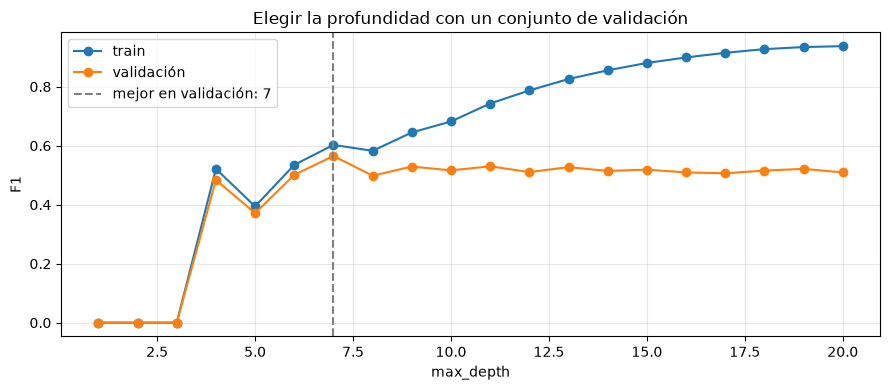

In [10]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEMILLA)   # 0,25 × 0,8 = 0,2

print(f"train {len(X_tr):,} | validación {len(X_val):,} | test {len(X_test):,}")

profundidades = range(1, 21)
f1_tr, f1_val = [], []
for p in profundidades:
    arbol = make_pipeline(SimpleImputer(strategy="median"),
                          DecisionTreeClassifier(max_depth=p, random_state=SEMILLA))
    arbol.fit(X_tr, y_tr)
    f1_tr.append(f1_score(y_tr, arbol.predict(X_tr)))
    f1_val.append(f1_score(y_val, arbol.predict(X_val)))

mejor_p = profundidades[int(np.argmax(f1_val))]

fig, ax = plt.subplots()
ax.plot(profundidades, f1_tr, marker="o", label="train")
ax.plot(profundidades, f1_val, marker="o", label="validación")
ax.axvline(mejor_p, color="gray", ls="--", label=f"mejor en validación: {mejor_p}")
ax.set_xlabel("max_depth"); ax.set_ylabel("F1"); ax.legend()
ax.set_title("Elegir la profundidad con un conjunto de validación")
plt.tight_layout()
plt.show()

Dos cosas para mirar:

1. La curva de **train sube siempre**: un árbol más profundo memoriza mejor los datos con
   los que se entrenó. La de **validación sube y después baja**: a partir de cierta
   profundidad el árbol empieza a aprender ruido. Es el **sobreajuste** de la clase.
2. La profundidad elegida depende de **qué filas cayeron en validación**. Si cambiamos la
   semilla del split, la elección cambia. El hold-out tiene **varianza**.

### 1.3 Hold-out repetido (*random subsampling*)

Para ver esa varianza, repetimos el hold-out 30 veces con particiones al azar
(`ShuffleSplit`) y miramos cómo se distribuye el F1 de un mismo modelo:

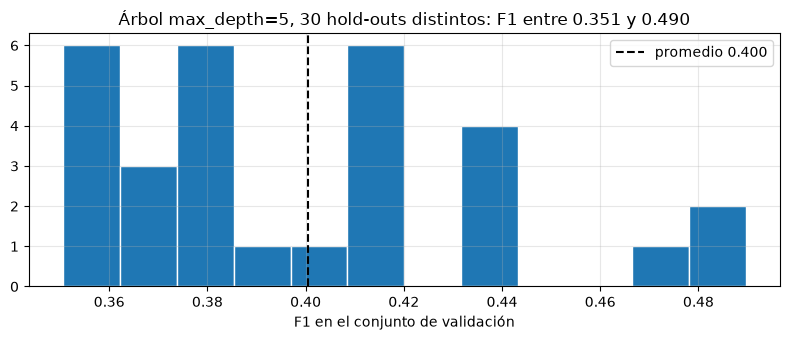

In [11]:
arbol5 = make_pipeline(SimpleImputer(strategy="median"),
                       DecisionTreeClassifier(max_depth=5, random_state=SEMILLA))

repetido = cross_val_score(arbol5, X_train, y_train, scoring="f1",
                           cv=ShuffleSplit(n_splits=30, test_size=0.25, random_state=SEMILLA))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(repetido, bins=12, edgecolor="white")
ax.axvline(repetido.mean(), color="black", ls="--", label=f"promedio {repetido.mean():.3f}")
ax.set_xlabel("F1 en el conjunto de validación"); ax.legend()
ax.set_title(f"Árbol max_depth=5, 30 hold-outs distintos: F1 entre {repetido.min():.3f} y {repetido.max():.3f}")
plt.tight_layout()
plt.show()

El mismo modelo, con los mismos datos, da resultados distintos según la partición. Un solo
hold-out es **una muestra** de esa distribución. El promedio de muchas repeticiones es una
estimación más confiable. El problema de repetir al azar es que algunas filas caen muchas
veces en validación y otras nunca. La validación cruzada lo resuelve.

---

## 2. Validación cruzada

**K-Fold:** se parte el conjunto en K partes (*folds*) de igual tamaño. Se entrena K veces,
cada vez dejando afuera un fold distinto para validar, y se promedian las K medidas.

- Cada fila se usa para validar **exactamente una vez**.
- K = 5 o K = 10 son "los K mágicos": empíricamente dan estimaciones sin demasiado sesgo ni
  demasiada varianza.
- **StratifiedKFold** además mantiene la proporción de clases en cada fold. Es lo que
  corresponde en clasificación (y lo que sklearn usa por defecto con `cv=5` en clasificadores).

### 2.1 Cómo se arman los folds

Para que se vea, tomamos 60 filas y graficamos a qué fold de validación cae cada una:

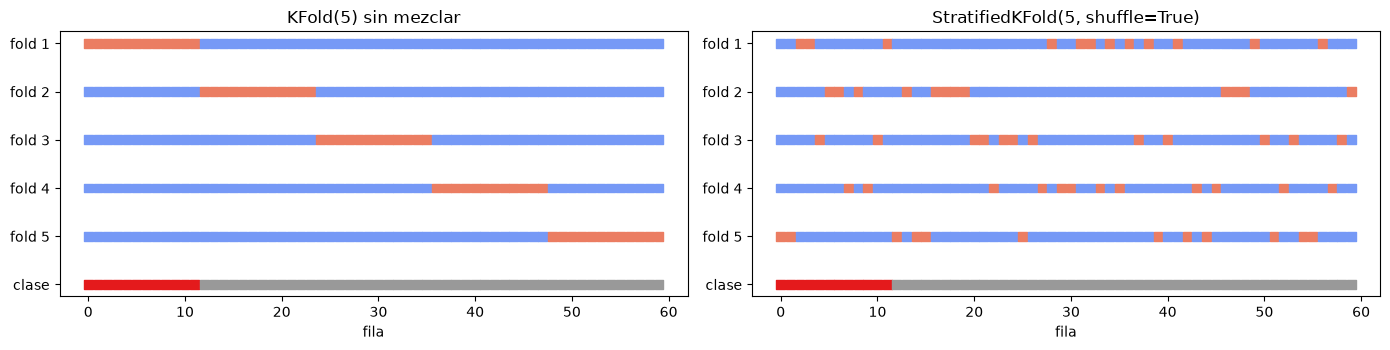

In [12]:
def graficar_folds(cv, X_, y_, ax, titulo):
    for i, (_, idx_val) in enumerate(cv.split(X_, y_)):
        fila = np.zeros(len(X_))
        fila[idx_val] = 1
        ax.scatter(range(len(X_)), [i] * len(X_), c=fila, cmap="coolwarm", marker="s", s=40, vmin=-0.3, vmax=1.3)
    ax.scatter(range(len(X_)), [cv.get_n_splits()] * len(X_), c=y_, cmap="Set1_r", marker="s", s=40)
    ax.set_yticks(range(cv.get_n_splits() + 1),
                  [f"fold {i + 1}" for i in range(cv.get_n_splits())] + ["clase"])
    ax.set_title(titulo); ax.set_xlabel("fila"); ax.invert_yaxis(); ax.grid(False)

# 60 filas ordenadas por clase, para que se note el efecto de estratificar
mini = pd.concat([X_train[y_train == 1].head(12), X_train[y_train == 0].head(48)])
y_mini = y_train.loc[mini.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
graficar_folds(KFold(5), mini, y_mini, axes[0], "KFold(5) sin mezclar")
graficar_folds(StratifiedKFold(5, shuffle=True, random_state=SEMILLA), mini, y_mini, axes[1],
               "StratifiedKFold(5, shuffle=True)")
plt.tight_layout()
plt.show()

En rojo, las filas que van a validación en cada fold; la última fila muestra la clase
(rojo = positivo). Con `KFold` sin mezclar y los datos ordenados, **todos los positivos
caen en el fold 1**: el modelo de ese fold se entrena sin ver un solo positivo. El
`StratifiedKFold` reparte los positivos parejo entre los folds.

### 2.2 `cross_val_score` y `cross_validate`

`cross_val_score` devuelve una métrica por fold. `cross_validate` permite pedir varias
métricas a la vez y, con `return_train_score=True`, también la de train.

In [13]:
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
CV10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)

for nombre, cv in [("5-fold", CV5), ("10-fold", CV10)]:
    s = cross_val_score(arbol5, X_train, y_train, cv=cv, scoring="f1")
    print(f"{nombre:8s} F1 por fold: {np.round(s, 3)}  →  {s.mean():.3f} ± {s.std():.3f}")

5-fold   F1 por fold: [0.357 0.437 0.4   0.482 0.37 ]  →  0.409 ± 0.046


10-fold  F1 por fold: [0.315 0.396 0.458 0.432 0.447 0.347 0.356 0.395 0.357 0.375]  →  0.388 ± 0.044


### 2.3 Leave-One-Out

Es K-Fold llevado al extremo: K = n. Cada modelo se entrena con todas las filas menos una y
se valida con esa. Tiene poco sesgo (cada modelo ve casi todos los datos) pero es **caro**:
hay que entrenar n modelos. Además, como cada validación es de una sola fila, sólo se puede
calcular accuracy por fold; para F1 hay que juntar las n predicciones (`cross_val_predict`).

Lo probamos sobre una submuestra de 400 filas y comparamos tiempos:

In [14]:
sub = X_train.sample(400, random_state=SEMILLA)
y_sub = y_train.loc[sub.index]

for nombre, cv in [("5-fold", StratifiedKFold(5, shuffle=True, random_state=SEMILLA)),
                   ("LOO", LeaveOneOut())]:
    t0 = time.perf_counter()
    pred = cross_val_predict(arbol5, sub, y_sub, cv=cv)
    seg = time.perf_counter() - t0
    print(f"{nombre:7s} modelos entrenados: {cv.get_n_splits(sub):4d} | "
          f"F1 {f1_score(y_sub, pred):.3f} | {seg:.2f} s")

5-fold  modelos entrenados:    5 | F1 0.660 | 0.02 s


LOO     modelos entrenados:  400 | F1 0.704 | 1.55 s


Con 400 filas, LOO entrena 400 modelos; con las 13 mil del train serían 13 mil. Por eso en
la práctica se usa K-Fold con K = 5 o 10. **De acá en adelante, todo se valida con
`StratifiedKFold(5)` sobre el conjunto de train.**

---

## 3. Línea base: el modelo que no aprende nada

Antes de entrenar cualquier cosa conviene saber **cuánto da un modelo trivial**. El
`DummyClassifier` predice siempre la clase más frecuente: "ningún alumno fracasa".

In [15]:
dummy = DummyClassifier(strategy="most_frequent")
r = cross_validate(dummy, X_train, y_train, cv=CV5, scoring=["accuracy", "f1", "recall"])

print(f"accuracy: {r['test_accuracy'].mean():.3f}")
print(f"recall  : {r['test_recall'].mean():.3f}")
print(f"F1      : {r['test_f1'].mean():.3f}")

accuracy: 0.896
recall  : 0.000
F1      : 0.000


**~90 % de accuracy sin aprender nada.** Un modelo que reporte "89 % de accuracy" en este
problema es *peor* que no hacer nada. Y el modelo trivial no detecta a ningún alumno en
riesgo (recall 0), que es justamente para lo que querríamos el modelo.

Con clases desbalanceadas, el accuracy no sirve para comparar. Necesitamos métricas que
miren específicamente a la clase positiva.

---

## 4. Medidas de performance

### 4.1 Matriz de confusión

Usamos el árbol de profundidad 5 y obtenemos sus predicciones con `cross_val_predict`: cada
fila de train se predice con el modelo del fold en el que **no** participó. Son predicciones
"fuera de muestra" sin tocar el test.

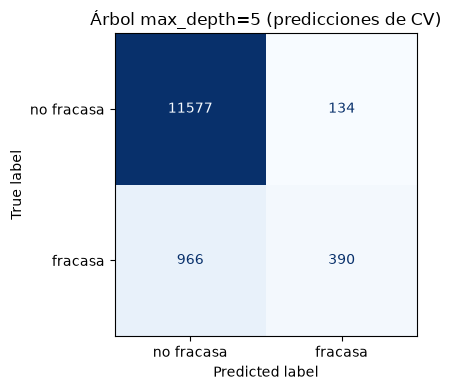

TP=390  FP=134  FN=966  TN=11577


In [16]:
pred_oof = cross_val_predict(arbol5, X_train, y_train, cv=CV5)
proba_oof = cross_val_predict(arbol5, X_train, y_train, cv=CV5, method="predict_proba")[:, 1]

cm = confusion_matrix(y_train, pred_oof)
TN, FP, FN, TP = cm.ravel()

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=["no fracasa", "fracasa"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Árbol max_depth=5 (predicciones de CV)")
ax.grid(False)
plt.tight_layout()
plt.show()

print(f"TP={TP}  FP={FP}  FN={FN}  TN={TN}")

|  | Predice **no** | Predice **sí** |
| --- | --- | --- |
| **Real no** | TN: verdadero negativo | FP: falso positivo |
| **Real sí** | FN: falso negativo | TP: verdadero positivo |

### 4.2 Las métricas, a mano

| Métrica | Fórmula | Pregunta que responde |
| --- | --- | --- |
| **Accuracy** | (TP + TN) / total | ¿Qué proporción clasifica bien? |
| **Error rate** | 1 − accuracy | ¿Qué proporción clasifica mal? |
| **Precisión** | TP / (TP + FP) | De los que el modelo marca como positivos, ¿cuántos lo son? |
| **Recall / Sensibilidad** | TP / (TP + FN) | De los positivos reales, ¿cuántos detecta? |
| **Especificidad** | TN / (TN + FP) | De los negativos reales, ¿cuántos reconoce? |
| **F1** | 2 · P · R / (P + R) | Media armónica de precisión y recall |
| **F-β** | (1 + β²) · P · R / (β² · P + R) | Como F1, pero el recall pesa β veces más |
| **Kappa** | (Pr(a) − Pr(e)) / (1 − Pr(e)) | ¿Cuánto mejor que el azar coincide con la realidad? |

Para kappa: Pr(a) es la coincidencia observada (el accuracy) y Pr(e) la coincidencia que se
esperaría por azar dadas las proporciones de cada clase:
Pr(e) = (pred. sí / total) · (real sí / total) + (pred. no / total) · (real no / total).

In [17]:
total = TP + TN + FP + FN
acc = (TP + TN) / total
prec = TP / (TP + FP)
rec = TP / (TP + FN)
espec = TN / (TN + FP)
f1 = 2 * prec * rec / (prec + rec)
beta = 2
f2 = (1 + beta**2) * prec * rec / (beta**2 * prec + rec)
pr_e = ((TP + FP) / total) * ((TP + FN) / total) + ((TN + FN) / total) * ((TN + FP) / total)
kappa = (acc - pr_e) / (1 - pr_e)

pd.DataFrame({
    "a mano": [acc, 1 - acc, prec, rec, espec, f1, f2, kappa],
    "sklearn": [accuracy_score(y_train, pred_oof), 1 - accuracy_score(y_train, pred_oof),
                precision_score(y_train, pred_oof), recall_score(y_train, pred_oof),
                recall_score(y_train, pred_oof, pos_label=0), f1_score(y_train, pred_oof),
                fbeta_score(y_train, pred_oof, beta=2), cohen_kappa_score(y_train, pred_oof)],
}, index=["accuracy", "error rate", "precisión", "recall", "especificidad", "F1", "F2", "kappa"])

,a mano,sklearn
accuracy,0.916,0.916
error rate,0.084,0.084
precisión,0.744,0.744
recall,0.288,0.288
especificidad,0.989,0.989
F1,0.415,0.415
F2,0.328,0.328
kappa,0.379,0.379


El accuracy sigue alto, pero ahora vemos lo que esconde. La **precisión** y el **recall**
miden cosas distintas y suelen moverse en sentidos opuestos:

- Para una tutoría preventiva, un **falso negativo** (no detectar a quien va a fracasar) es
  más caro que un **falso positivo** (ofrecer tutoría a quien no la necesitaba). Ahí conviene
  priorizar el recall, por ejemplo con F2.
- Si la intervención fuera cara o invasiva, convendría priorizar la precisión.

**Qué métrica optimizar es una decisión del problema, no de la técnica.** En esta notebook
optimizamos F1 como compromiso.

`classification_report` resume todo por clase:

In [18]:
print(classification_report(y_train, pred_oof, target_names=["no fracasa", "fracasa"], digits=3))

              precision    recall  f1-score   support

  no fracasa      0.923     0.989     0.955     11711
     fracasa      0.744     0.288     0.415      1356

    accuracy                          0.916     13067
   macro avg      0.834     0.638     0.685     13067
weighted avg      0.904     0.916     0.899     13067



### 4.3 Curva ROC y curva Precisión-Recall

Los clasificadores no devuelven directamente 0 o 1: devuelven una **probabilidad** (o un
puntaje), y la clase sale de compararla con un **umbral**, por defecto 0,5. Cada umbral da
una matriz de confusión distinta.

- La **curva ROC** grafica, para todos los umbrales, la tasa de verdaderos positivos
  (recall) contra la tasa de falsos positivos (1 − especificidad). El **AUC** (área bajo la
  curva) resume la curva en un número: 0,5 es azar (la diagonal), 1 es perfecto.
- La **curva Precisión-Recall** es más informativa con clases desbalanceadas: la ROC puede
  verse muy bien aunque la precisión sea baja, porque la tasa de falsos positivos se divide
  por la cantidad de negativos, que es enorme. La línea base de la PR es la proporción de
  positivos.

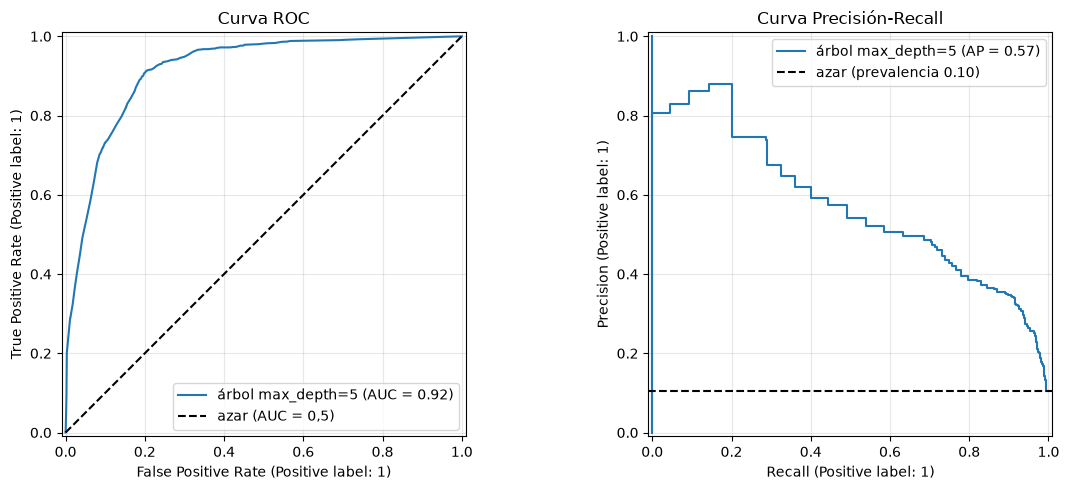

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

RocCurveDisplay.from_predictions(y_train, proba_oof, name="árbol max_depth=5", ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", label="azar (AUC = 0,5)")
axes[0].set_title("Curva ROC"); axes[0].legend(loc="lower right")

PrecisionRecallDisplay.from_predictions(y_train, proba_oof, name="árbol max_depth=5", ax=axes[1])
axes[1].axhline(y_train.mean(), color="k", ls="--", label=f"azar (prevalencia {y_train.mean():.2f})")
axes[1].set_title("Curva Precisión-Recall"); axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

La curva del árbol es escalonada porque un árbol de profundidad 5 tiene pocas hojas, y
cada hoja da una sola probabilidad: hay pocos umbrales distintos.

---

## 5. Árbol de decisión

Scikit-learn implementa **CART**: árboles binarios (cada nodo divide en dos) que eligen en
cada nodo la variable y el punto de corte que más reducen la impureza. La impureza se puede
medir con **Gini** (por defecto) o con **entropía**, que es la medida de ID3 / C4.5. Las
variables continuas se manejan buscando el mejor umbral, como en C4.5.

### 5.1 Un árbol sin restricciones

In [20]:
arbol_libre = make_pipeline(SimpleImputer(strategy="median"),
                            DecisionTreeClassifier(random_state=SEMILLA))

r = cross_validate(arbol_libre, X_train, y_train, cv=CV5, scoring=["accuracy", "f1"],
                   return_train_score=True)
arbol_libre.fit(X_train, y_train)
t = arbol_libre[-1]

print(f"profundidad {t.get_depth()} | {t.get_n_leaves():,} hojas")
print(f"accuracy  train {r['train_accuracy'].mean():.3f}  |  CV {r['test_accuracy'].mean():.3f}")
print(f"F1        train {r['train_f1'].mean():.3f}  |  CV {r['test_f1'].mean():.3f}")

profundidad 29 | 1,455 hojas
accuracy  train 0.988  |  CV 0.896
F1        train 0.941  |  CV 0.496


Un árbol sin límites crece hasta que cada hoja es pura: **memoriza** el entrenamiento
(train casi perfecto), con cientos de hojas, y generaliza mal. Es el ejemplo de manual del
sobreajuste: tiene **bajo sesgo y alta varianza**.

### 5.2 Curva de validación: el compromiso sesgo–varianza

`validation_curve` hace lo mismo que el loop de la sección 1.2, pero con validación cruzada
en lugar de un solo hold-out: para cada valor del hiperparámetro, F1 promedio de train y de
CV, con su desvío.

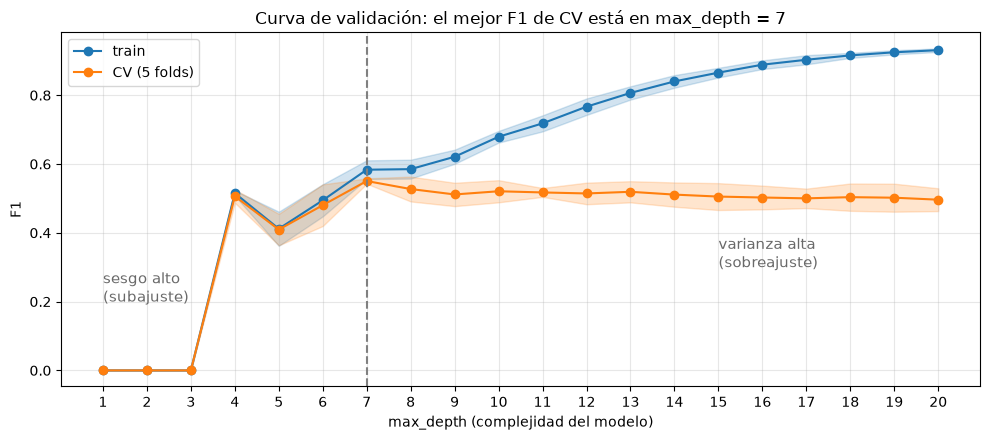

In [21]:
profundidades = np.arange(1, 21)
f1_train, f1_cv = validation_curve(
    make_pipeline(SimpleImputer(strategy="median"), DecisionTreeClassifier(random_state=SEMILLA)),
    X_train, y_train, param_name="decisiontreeclassifier__max_depth",
    param_range=profundidades, cv=CV5, scoring="f1", n_jobs=-1)

media_cv = f1_cv.mean(axis=1)
mejor = profundidades[media_cv.argmax()]

fig, ax = plt.subplots(figsize=(10, 4.5))
for nombre, m, color in [("train", f1_train, "tab:blue"), ("CV (5 folds)", f1_cv, "tab:orange")]:
    ax.plot(profundidades, m.mean(axis=1), marker="o", color=color, label=nombre)
    ax.fill_between(profundidades, m.mean(axis=1) - m.std(axis=1), m.mean(axis=1) + m.std(axis=1),
                    color=color, alpha=0.2)
ax.axvline(mejor, color="gray", ls="--")
ax.text(1, 0.2, "sesgo alto\n(subajuste)", fontsize=11, color="dimgray")
ax.text(15, 0.3, "varianza alta\n(sobreajuste)", fontsize=11, color="dimgray")
ax.set_xticks(profundidades)
ax.set_xlabel("max_depth (complejidad del modelo)"); ax.set_ylabel("F1"); ax.legend(loc="upper left")
ax.set_title(f"Curva de validación: el mejor F1 de CV está en max_depth = {mejor}")
plt.tight_layout()
plt.show()

Es el gráfico de la clase con datos reales:

- **A la izquierda**, árboles muy chicos: les va igual de mal en train y en CV. El modelo es
  demasiado rígido para capturar el patrón (**sesgo alto**). Con profundidad 1 a 3 el árbol
  ni siquiera llega a tener una hoja con mayoría de positivos: predice "no fracasa" para
  todos, igual que el dummy, y el F1 es 0.
- **A la derecha**, árboles muy profundos: train sigue mejorando, CV empeora y la banda de
  desvío se ensancha. El modelo se adapta a la idiosincrasia de cada conjunto de
  entrenamiento (**varianza alta**).
- El punto óptimo está en el medio, donde el error de CV es mínimo.

### 5.3 Gini o entropía

In [22]:
for criterio in ["gini", "entropy"]:
    m = make_pipeline(SimpleImputer(strategy="median"),
                      DecisionTreeClassifier(criterion=criterio, max_depth=mejor, random_state=SEMILLA))
    s = cross_val_score(m, X_train, y_train, cv=CV5, scoring="f1")
    print(f"{criterio:8s} F1 CV = {s.mean():.3f} ± {s.std():.3f}")

gini     F1 CV = 0.551 ± 0.008
entropy  F1 CV = 0.561 ± 0.016


En la práctica Gini y entropía casi siempre dan árboles muy parecidos. La elección de
`criterion` pesa mucho menos que la de los parámetros que controlan el **tamaño** del árbol.

### 5.4 Búsqueda de hiperparámetros con validación cruzada

`GridSearchCV` prueba **todas las combinaciones** de una grilla de hiperparámetros, evalúa
cada una con validación cruzada y se queda con la mejor. Después reentrena esa combinación
con todo el train (`refit`). Los hiperparámetros del árbol que vamos a explorar:

| Hiperparámetro | Qué controla |
| --- | --- |
| `max_depth` | Profundidad máxima |
| `min_samples_leaf` | Mínimo de filas en cada hoja: evita hojas que representan 1 o 2 casos |
| `class_weight` | `"balanced"` pesa cada clase en forma inversa a su frecuencia: los errores sobre la clase minoritaria cuestan más |
| `criterion` | Gini o entropía |

Con `scoring` en forma de diccionario se registran varias métricas, y `refit="f1"` indica
cuál se usa para elegir.

In [23]:
METRICAS = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
            "recall": "recall",
            "f1": "f1", "roc_auc": "roc_auc", "kappa": make_scorer(cohen_kappa_score)}

grilla_arbol = {
    "decisiontreeclassifier__max_depth": [3, 4, 5, 6, 8, 10, 12],
    "decisiontreeclassifier__min_samples_leaf": [1, 10, 50, 100],
    "decisiontreeclassifier__class_weight": [None, "balanced"],
    "decisiontreeclassifier__criterion": ["gini", "entropy"],
}

gs_arbol = GridSearchCV(
    make_pipeline(SimpleImputer(strategy="median"), DecisionTreeClassifier(random_state=SEMILLA)),
    grilla_arbol, cv=CV5, scoring=METRICAS, refit="f1", n_jobs=-1)

t0 = time.perf_counter()
gs_arbol.fit(X_train, y_train)
n_comb = len(gs_arbol.cv_results_["params"])
print(f"{n_comb} combinaciones × 5 folds = {n_comb * 5} árboles en {time.perf_counter() - t0:.1f} s")
print("Mejor combinación:", {k.split("__")[1]: v for k, v in gs_arbol.best_params_.items()})
print(f"F1 CV: {gs_arbol.best_score_:.3f}")

112 combinaciones × 5 folds = 560 árboles en 6.0 s
Mejor combinación: {'class_weight': None, 'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 50}
F1 CV: 0.559


In [24]:
def tabla_resultados(gs, n=8):
    # Las mejores n combinaciones, con todas las métricas
    res = pd.DataFrame(gs.cv_results_)
    params = pd.DataFrame([{k.split("__")[1]: ("None" if v is None else v) for k, v in p.items()}
                           for p in res["params"]], index=res.index)
    metricas = res[[f"mean_test_{m}" for m in METRICAS]].rename(columns=lambda c: c.replace("mean_test_", ""))
    return pd.concat([params, metricas], axis=1).sort_values("f1", ascending=False).head(n)

tabla_resultados(gs_arbol)

,class_weight,criterion,max_depth,min_samples_leaf,accuracy,precision,recall,f1,roc_auc,kappa
54,None,entropy,12,50,0.924,0.709,0.465,0.559,0.920,0.520
50,None,entropy,10,50,0.924,0.709,0.465,0.559,0.921,0.520
26,None,gini,12,50,0.924,0.705,0.459,0.556,0.922,0.516
22,None,gini,10,50,0.924,0.705,0.459,0.556,0.922,0.516
53,None,entropy,12,10,0.920,0.662,0.464,0.545,0.891,0.502
27,None,gini,12,100,0.924,0.732,0.420,0.533,0.924,0.494
19,None,gini,8,100,0.924,0.732,0.420,0.533,0.924,0.494
23,None,gini,10,100,0.924,0.732,0.420,0.533,0.924,0.494


Un heatmap de F1 de CV, para `max_depth` × `min_samples_leaf`, fijando `class_weight` y
`criterion` en los valores ganadores:

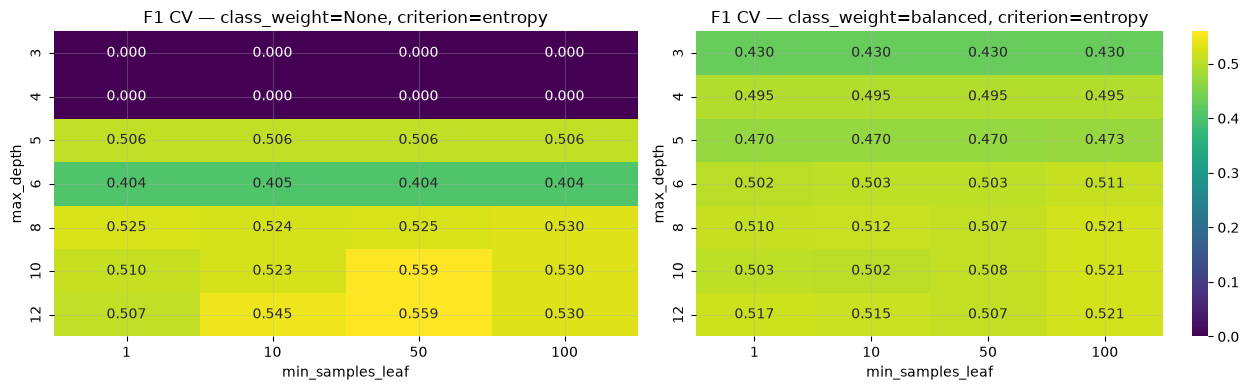

In [25]:
res = pd.DataFrame(gs_arbol.cv_results_)
mejor_cw = gs_arbol.best_params_["decisiontreeclassifier__class_weight"]
mejor_crit = gs_arbol.best_params_["decisiontreeclassifier__criterion"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, cw in zip(axes, [None, "balanced"]):
    filtro = res["params"].apply(lambda p: p["decisiontreeclassifier__class_weight"] == cw
                                 and p["decisiontreeclassifier__criterion"] == mejor_crit)
    tabla = res[filtro].pivot_table(index="param_decisiontreeclassifier__max_depth",
                                    columns="param_decisiontreeclassifier__min_samples_leaf",
                                    values="mean_test_f1")
    sns.heatmap(tabla, annot=True, fmt=".3f", cmap="viridis", ax=ax, vmin=res.mean_test_f1.min(),
                vmax=res.mean_test_f1.max(), cbar=ax is axes[1])
    ax.set_title(f"F1 CV — class_weight={cw}, criterion={mejor_crit}")
    ax.set_xlabel("min_samples_leaf"); ax.set_ylabel("max_depth")
plt.tight_layout()
plt.show()

El heatmap permite ver **la forma** del espacio de búsqueda y no sólo el máximo:

- Si la mejor combinación está en un borde de la grilla, convendría ampliarla en esa
  dirección.
- Si hay una meseta de valores parecidos, conviene elegir el modelo **más simple** dentro de
  ella: es la navaja de Occam de la clase, que en un árbol significa menos profundidad y
  hojas más grandes.
- La comparación entre los dos paneles muestra el efecto de `class_weight="balanced"` en un
  problema desbalanceado.

### 5.5 Poda por costo-complejidad

En lugar de cortar el crecimiento con `max_depth`, se puede dejar crecer el árbol entero y
después **podarlo**, como hace C4.5. CART poda por **costo-complejidad**: a cada subárbol le
suma una penalización `α × (cantidad de hojas)`. Con α = 0 no se poda nada, y a medida que
α crece se van eliminando las ramas que menos aportan.

`cost_complexity_pruning_path` devuelve los valores de α en los que el árbol cambia.

540 valores de α en el camino de poda


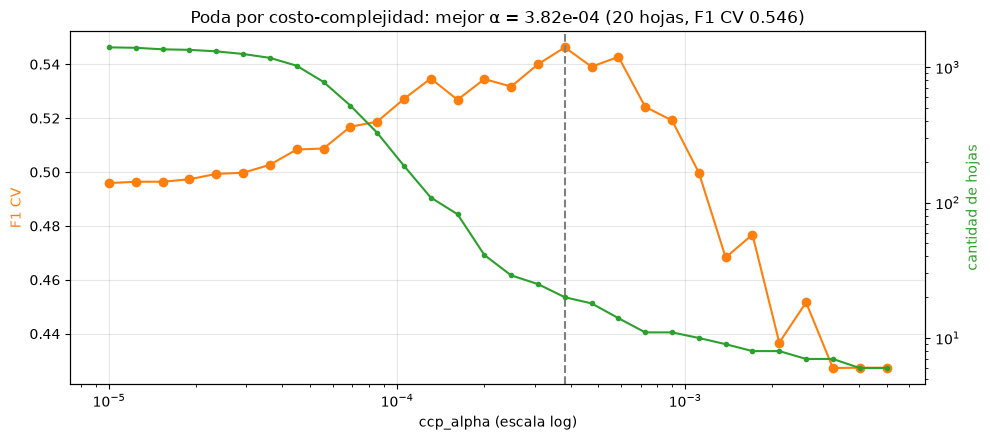

In [26]:
imputador = SimpleImputer(strategy="median").fit(X_train)
camino = DecisionTreeClassifier(random_state=SEMILLA).cost_complexity_pruning_path(
    imputador.transform(X_train), y_train)

print(f"{len(camino.ccp_alphas):,} valores de α en el camino de poda")

# Son demasiados para probarlos todos: tomamos 30 repartidos en escala logarítmica
alphas = np.geomspace(1e-5, 5e-3, 30)

hojas, f1_alpha = [], []
for a in alphas:
    m = make_pipeline(SimpleImputer(strategy="median"),
                      DecisionTreeClassifier(ccp_alpha=a, random_state=SEMILLA))
    f1_alpha.append(cross_val_score(m, X_train, y_train, cv=CV5, scoring="f1", n_jobs=-1).mean())
    hojas.append(m.fit(X_train, y_train)[-1].get_n_leaves())

alpha_opt = alphas[int(np.argmax(f1_alpha))]

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.semilogx(alphas, f1_alpha, marker="o", color="tab:orange", label="F1 CV")
ax1.set_xlabel("ccp_alpha (escala log)"); ax1.set_ylabel("F1 CV", color="tab:orange")
ax2 = ax1.twinx()
ax2.semilogx(alphas, hojas, marker=".", color="tab:green", label="hojas")
ax2.set_ylabel("cantidad de hojas", color="tab:green"); ax2.set_yscale("log"); ax2.grid(False)
ax1.axvline(alpha_opt, color="gray", ls="--")
ax1.set_title(f"Poda por costo-complejidad: mejor α = {alpha_opt:.2e} "
              f"({hojas[int(np.argmax(f1_alpha))]} hojas, F1 CV {max(f1_alpha):.3f})")
plt.tight_layout()
plt.show()

Al aumentar α, el árbol pasa de cientos de hojas a una sola. El F1 de CV **mejora** al
principio (se podan ramas que eran sobreajuste) y después cae (se podan ramas útiles). Es
otra vez la curva de sesgo–varianza, recorrida en la dirección contraria.

### 5.6 El árbol, graficado

Tomamos el mejor árbol de la búsqueda y lo graficamos con `plot_tree`. Si es profundo, el
gráfico completo no se lee, así que mostramos los **primeros 3 niveles** (`max_depth=3` en
`plot_tree` sólo trunca el dibujo, no el modelo).

Cómo se lee cada nodo:

- **condición** (`variable <= umbral`): las filas que la cumplen van a la izquierda.
- **gini / entropy**: impureza del nodo (0 = puro).
- **samples**: proporción de filas de train que llegan al nodo.
- **value**: proporción de cada clase en el nodo.
- **class**: clase mayoritaria. El color indica la clase, y su intensidad, qué tan puro es
  el nodo.

Mejor árbol: profundidad 10, 101 hojas


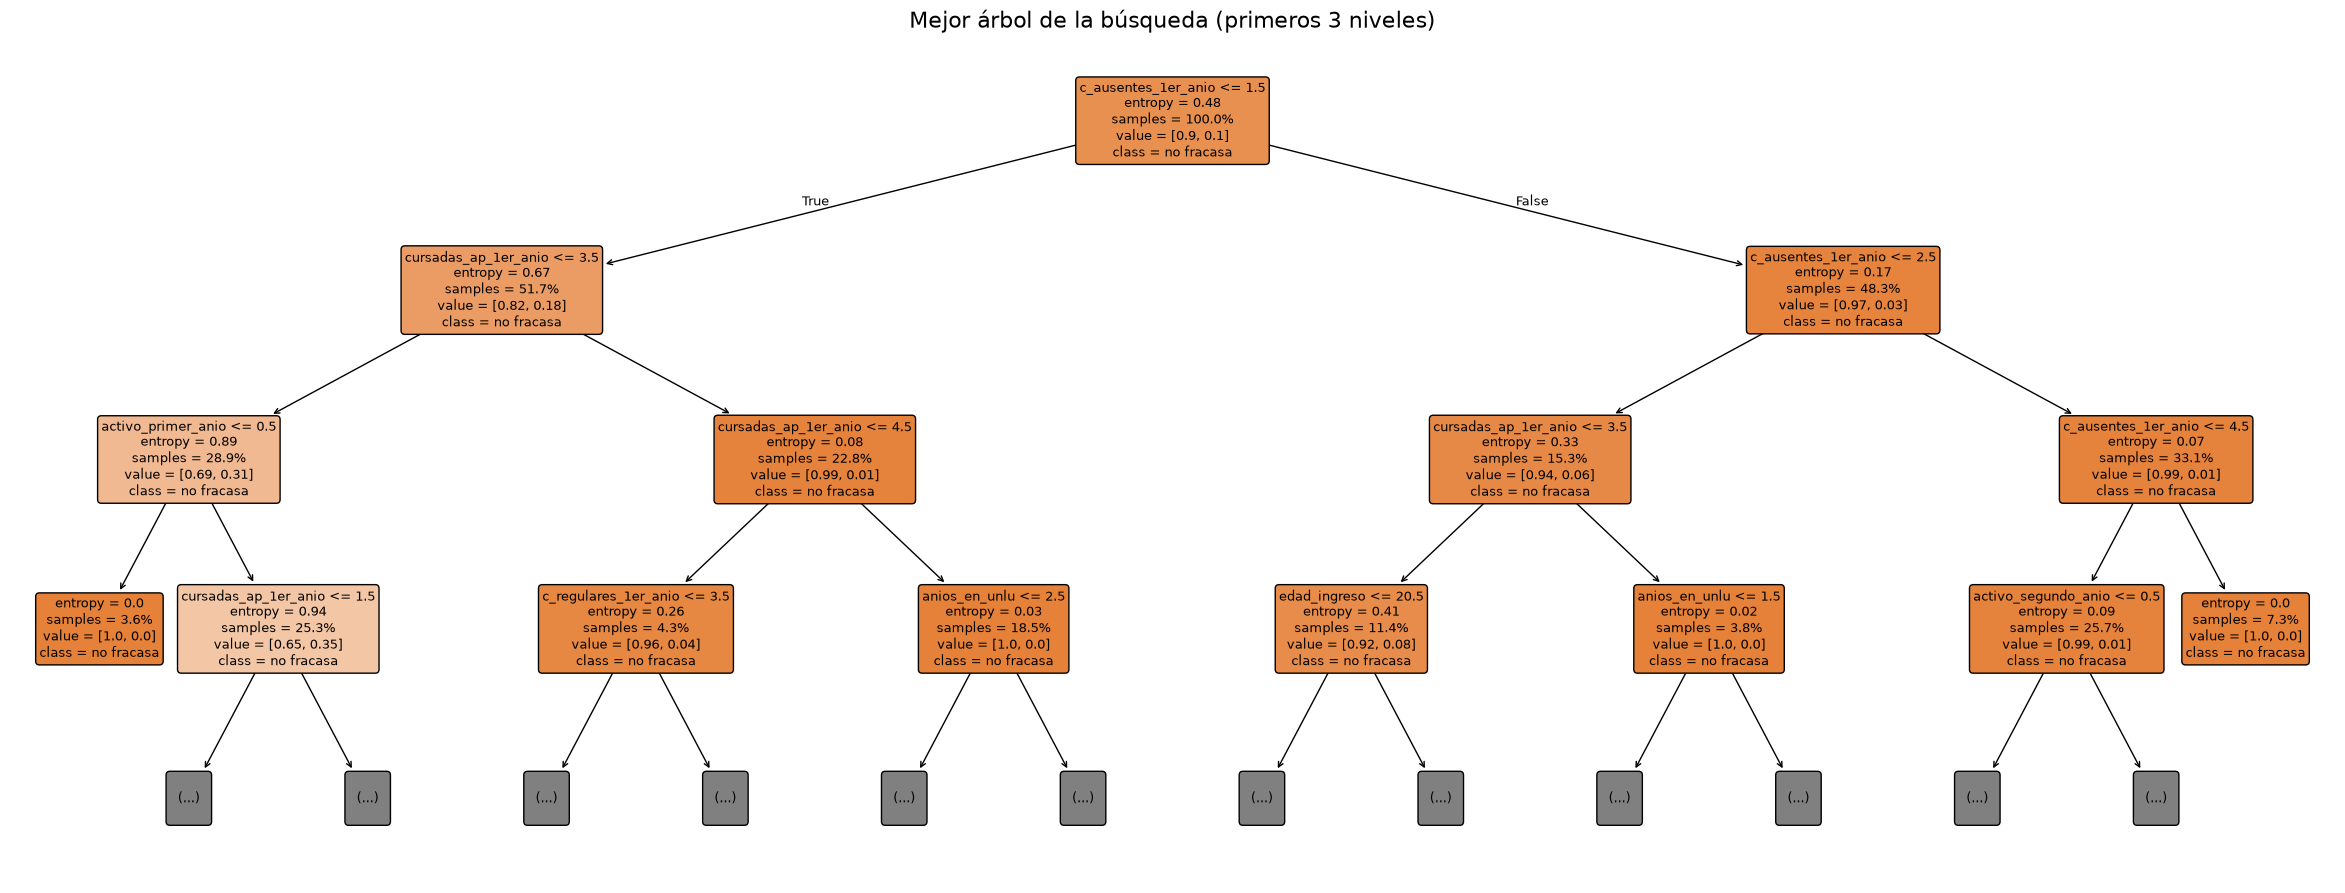

In [27]:
mejor_arbol = gs_arbol.best_estimator_[-1]
print(f"Mejor árbol: profundidad {mejor_arbol.get_depth()}, {mejor_arbol.get_n_leaves()} hojas")

fig, ax = plt.subplots(figsize=(30, 11))
plot_tree(mejor_arbol, max_depth=3, feature_names=VARIABLES, class_names=["no fracasa", "fracasa"],
          filled=True, rounded=True, proportion=True, precision=2, fontsize=9, ax=ax)
ax.set_title("Mejor árbol de la búsqueda (primeros 3 niveles)", fontsize=16)
plt.show()

F1 CV del árbol de profundidad 3: 0.430


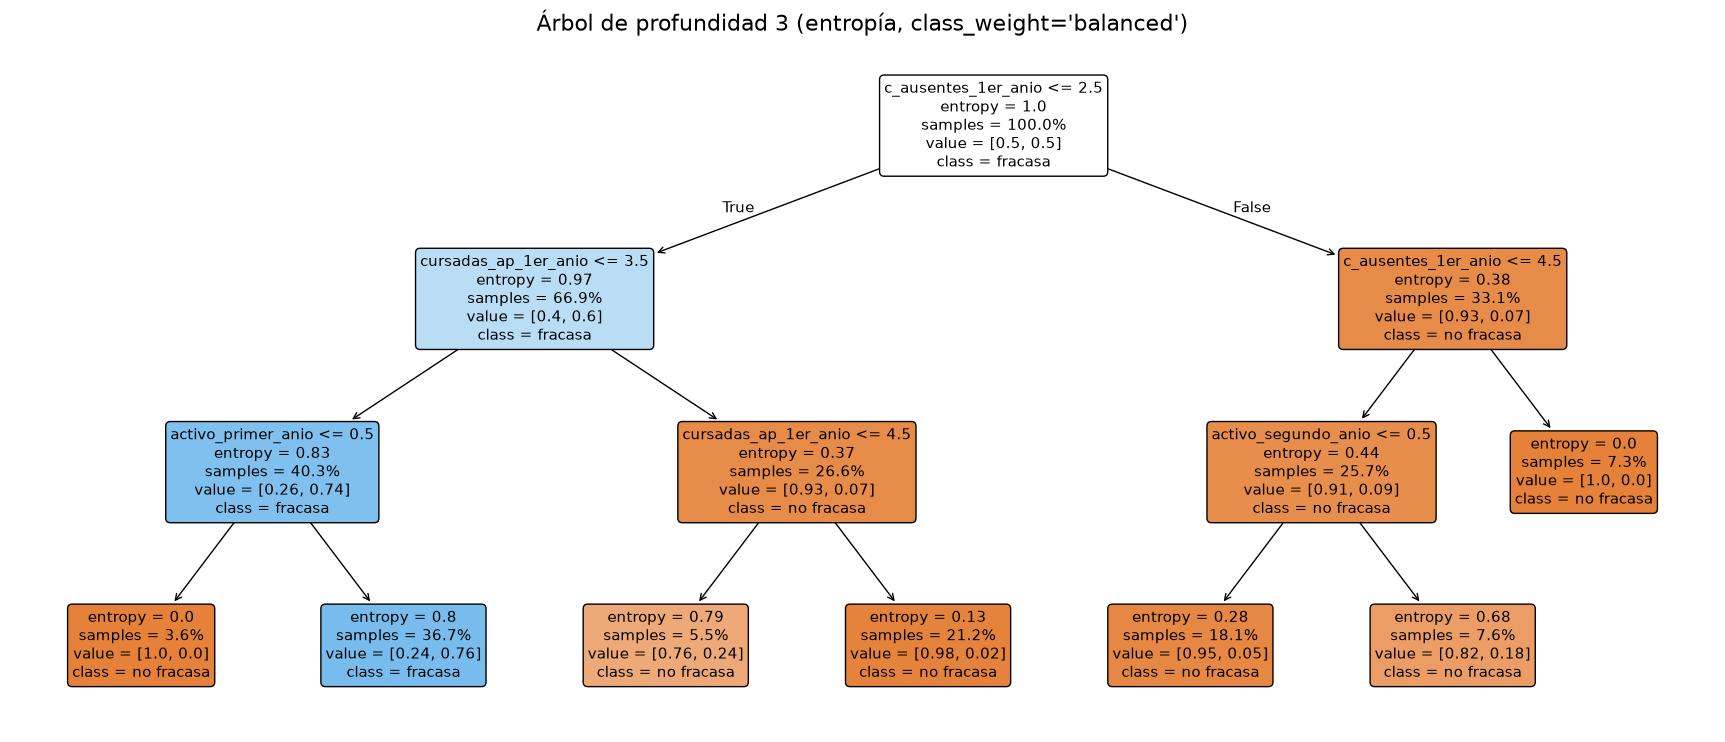

In [28]:
arbol3 = make_pipeline(SimpleImputer(strategy="median"),
                       DecisionTreeClassifier(max_depth=3, class_weight="balanced",
                                              criterion="entropy", random_state=SEMILLA))
arbol3.fit(X_train, y_train)
print(f"F1 CV del árbol de profundidad 3: "
      f"{cross_val_score(arbol3, X_train, y_train, cv=CV5, scoring='f1').mean():.3f}")

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(arbol3[-1], feature_names=VARIABLES, class_names=["no fracasa", "fracasa"],
          filled=True, rounded=True, proportion=True, precision=2, fontsize=11, ax=ax)
ax.set_title("Árbol de profundidad 3 (entropía, class_weight='balanced')", fontsize=16)
plt.show()

Dos cosas para mirar en este árbol:

- Con `class_weight="balanced"` la raíz arranca en `value = [0.5, 0.5]`: los pesos
  equilibran las clases, por eso el árbol se anima a declarar hojas como "fracasa".
- **Más ausencias, menos fracaso.** La rama de la derecha (`c_ausentes_1er_anio > 2.5`) es
  casi toda "no fracasa". Parece absurdo, pero es la fórmula de la sección 0.1: las ausentes
  cuentan en `cursadas_1er_anio`, que es el **denominador** de la proporción de libres. Con
  más ausentes es mecánicamente más difícil superar la mitad de libres. Aunque sacamos las
  columnas de la fórmula, el árbol encontró **restos de la fuga**. Un modelo puede tener buenas
  métricas y estar aprendiendo una regla administrativa, no un fenómeno educativo.
- Algunos cortes tienen las dos hojas con la misma clase (por ejemplo
  `cursadas_ap_1er_anio <= 4.5`). No es un error: el corte reduce la impureza (las
  proporciones cambian), aunque no cambie la clase mayoritaria.

El mismo árbol como **reglas de texto** con `export_text`. Cada camino de la raíz a una hoja
es una regla del tipo *SI … Y … ENTONCES clase*, y esa es la gran ventaja de los árboles:
el modelo se puede leer y explicar.

In [29]:
print(export_text(arbol3[-1], feature_names=VARIABLES, show_weights=False))

|--- c_ausentes_1er_anio <= 2.50
|   |--- cursadas_ap_1er_anio <= 3.50
|   |   |--- activo_primer_anio <= 0.50
|   |   |   |--- class: 0
|   |   |--- activo_primer_anio >  0.50
|   |   |   |--- class: 1
|   |--- cursadas_ap_1er_anio >  3.50
|   |   |--- cursadas_ap_1er_anio <= 4.50
|   |   |   |--- class: 0
|   |   |--- cursadas_ap_1er_anio >  4.50
|   |   |   |--- class: 0
|--- c_ausentes_1er_anio >  2.50
|   |--- c_ausentes_1er_anio <= 4.50
|   |   |--- activo_segundo_anio <= 0.50
|   |   |   |--- class: 0
|   |   |--- activo_segundo_anio >  0.50
|   |   |   |--- class: 0
|   |--- c_ausentes_1er_anio >  4.50
|   |   |--- class: 0



### 5.7 Importancia de las variables

`feature_importances_` mide cuánto contribuye cada variable a reducir la impureza, sumado
sobre todos los nodos donde se usa. Suma 1.

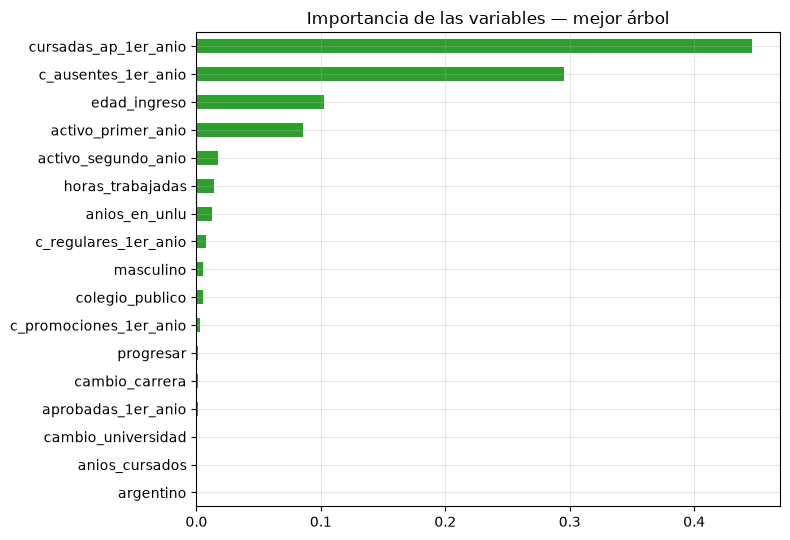

In [30]:
imp_arbol = pd.Series(mejor_arbol.feature_importances_, index=VARIABLES).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
imp_arbol.plot.barh(ax=ax, color="tab:green")
ax.set_title("Importancia de las variables — mejor árbol")
plt.tight_layout()
plt.show()

Dos advertencias para la interpretación:

- La importancia dice cuánto **usa** el modelo una variable, no si la relación es causal.
- Entre variables muy correlacionadas (por ejemplo `aprobadas_1er_anio` y
  `cursadas_ap_1er_anio`), el árbol suele elegir una y la otra queda con importancia baja,
  aunque sea igual de informativa.

---

## 6. Regresión logística

Un modelo de naturaleza muy distinta: en lugar de partir el espacio en rectángulos, estima
la probabilidad de la clase positiva como una función **lineal** de las variables, pasada
por la función logística:

$$P(y=1 \mid x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_p x_p)}}$$

Diferencias prácticas con el árbol:

- **Hay que estandarizar.** La regularización (el hiperparámetro `C`) penaliza el tamaño de
  los coeficientes, y eso sólo es justo si todas las variables están en la misma escala. El
  árbol, en cambio, es indiferente a la escala.
- `C` controla la complejidad: con `C` chico la regularización es fuerte y el modelo es más
  simple (más sesgo); con `C` grande, más flexible (más varianza).

El `StandardScaler` va **dentro del pipeline**, así que en cada fold se ajusta sólo con los
datos de entrenamiento de ese fold.

In [31]:
grilla_logistica = {
    "logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "logisticregression__class_weight": [None, "balanced"],
}

gs_logistica = GridSearchCV(
    make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                  LogisticRegression(max_iter=5000)),
    grilla_logistica, cv=CV5, scoring=METRICAS, refit="f1", n_jobs=-1)
gs_logistica.fit(X_train, y_train)

print("Mejor combinación:", {k.split("__")[1]: v for k, v in gs_logistica.best_params_.items()})
print(f"F1 CV: {gs_logistica.best_score_:.3f}")
tabla_resultados(gs_logistica, n=6)

Mejor combinación: {'C': 10, 'class_weight': None}
F1 CV: 0.532


,C,class_weight,accuracy,precision,recall,f1,roc_auc,kappa
8,10.0,None,0.921,0.689,0.434,0.532,0.924,0.491
10,100.0,None,0.921,0.689,0.434,0.532,0.924,0.491
6,1.0,None,0.921,0.689,0.430,0.529,0.924,0.488
9,10.0,balanced,0.832,0.370,0.873,0.519,0.924,0.437
11,100.0,balanced,0.832,0.370,0.873,0.519,0.924,0.437
7,1.0,balanced,0.832,0.369,0.872,0.519,0.924,0.436


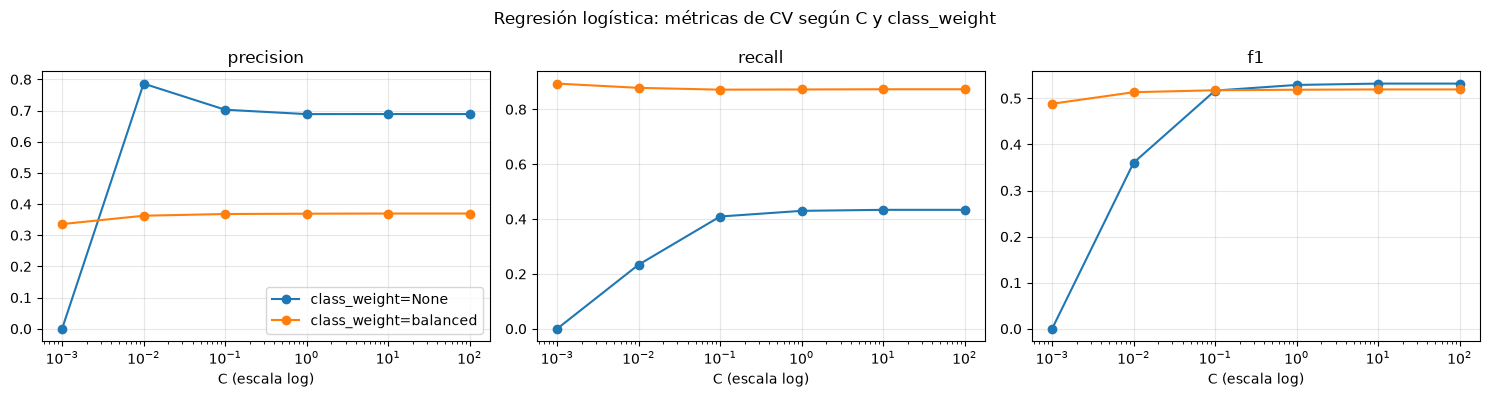

In [32]:
res = pd.DataFrame(gs_logistica.cv_results_)
res["class_weight"] = res["params"].apply(lambda p: str(p["logisticregression__class_weight"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, met in zip(axes, ["precision", "recall", "f1"]):
    for cw, g in res.groupby("class_weight"):
        ax.semilogx(g.param_logisticregression__C.astype(float), g[f"mean_test_{met}"],
                    marker="o", label=f"class_weight={cw}")
    ax.set_title(met); ax.set_xlabel("C (escala log)")
axes[0].legend()
fig.suptitle("Regresión logística: métricas de CV según C y class_weight")
plt.tight_layout()
plt.show()

Acá se ve con claridad qué hace `class_weight="balanced"`: el modelo pasa a marcar como
positivos a muchos más alumnos, así que el **recall sube mucho y la precisión baja**. El F1
decide cuál de los dos compromisos es mejor.

Como las variables están estandarizadas, los **coeficientes** son comparables entre sí:
indican cuánto cambia el *log-odds* de fracasar por cada desvío estándar de la variable.

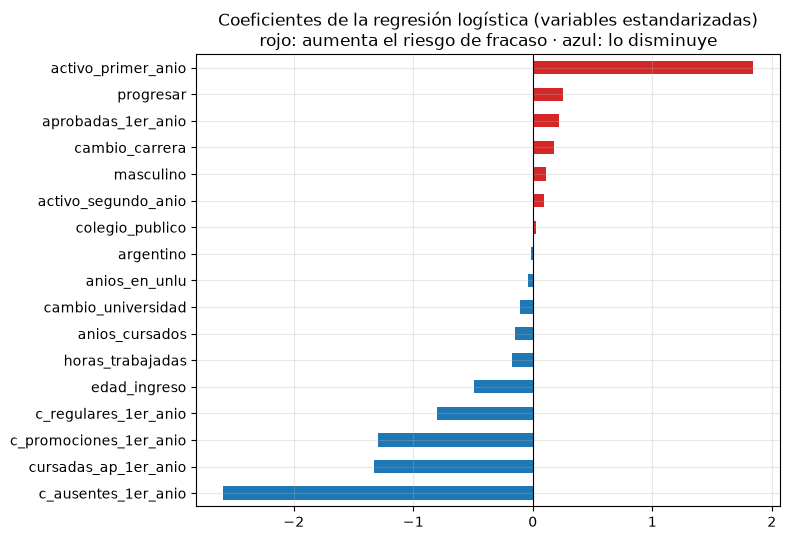

In [33]:
coefs = pd.Series(gs_logistica.best_estimator_[-1].coef_[0], index=VARIABLES).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
coefs.plot.barh(ax=ax, color=np.where(coefs > 0, "tab:red", "tab:blue"))
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Coeficientes de la regresión logística (variables estandarizadas)\n"
             "rojo: aumenta el riesgo de fracaso · azul: lo disminuye")
plt.tight_layout()
plt.show()

---

## 7. Random Forest

Un árbol solo tiene **alta varianza**: pequeños cambios en los datos producen árboles muy
distintos. Random Forest ataca justamente eso. Entrena **muchos árboles**, cada uno:

- con una muestra *bootstrap* de las filas (muestreo con reposición), y
- eligiendo en cada nodo el mejor corte entre un **subconjunto al azar de variables**
  (`max_features`),

y después **promedia** sus probabilidades. Cada árbol individual sobreajusta, pero como
sobreajustan de formas distintas, los errores se compensan y el promedio tiene mucha menos
varianza. A cambio se pierde la posibilidad de leer el modelo como un único árbol.

In [34]:
grilla_rf = {
    "randomforestclassifier__max_depth": [8, 12, None],
    "randomforestclassifier__min_samples_leaf": [1, 5, 20],
    "randomforestclassifier__max_features": ["sqrt", 0.5],
    "randomforestclassifier__class_weight": [None, "balanced_subsample"],
}

gs_rf = GridSearchCV(
    make_pipeline(SimpleImputer(strategy="median"),
                  RandomForestClassifier(n_estimators=300, random_state=SEMILLA)),   # paraleliza la búsqueda, no el bosque
    grilla_rf, cv=CV5, scoring=METRICAS, refit="f1", n_jobs=-1)

t0 = time.perf_counter()
gs_rf.fit(X_train, y_train)
print(f"{len(gs_rf.cv_results_['params'])} combinaciones en {time.perf_counter() - t0:.0f} s")
print("Mejor combinación:", {k.split("__")[1]: v for k, v in gs_rf.best_params_.items()})
print(f"F1 CV: {gs_rf.best_score_:.3f}")
tabla_resultados(gs_rf, n=6)

36 combinaciones en 71 s
Mejor combinación: {'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5}
F1 CV: 0.584


,class_weight,max_depth,max_features,min_samples_leaf,accuracy,precision,recall,f1,roc_auc,kappa
34,balanced_subsample,None,0.5,5,0.886,0.470,0.774,0.584,0.929,0.523
27,balanced_subsample,12,0.5,1,0.879,0.452,0.784,0.573,0.928,0.509
31,balanced_subsample,None,sqrt,5,0.874,0.441,0.816,0.573,0.931,0.506
28,balanced_subsample,12,0.5,5,0.872,0.437,0.819,0.570,0.930,0.502
24,balanced_subsample,12,sqrt,1,0.873,0.440,0.803,0.568,0.927,0.501
16,None,None,0.5,5,0.926,0.724,0.462,0.563,0.929,0.525


Las importancias del bosque promedian las de 300 árboles, así que son más estables que las
de un árbol solo. Comparémoslas:

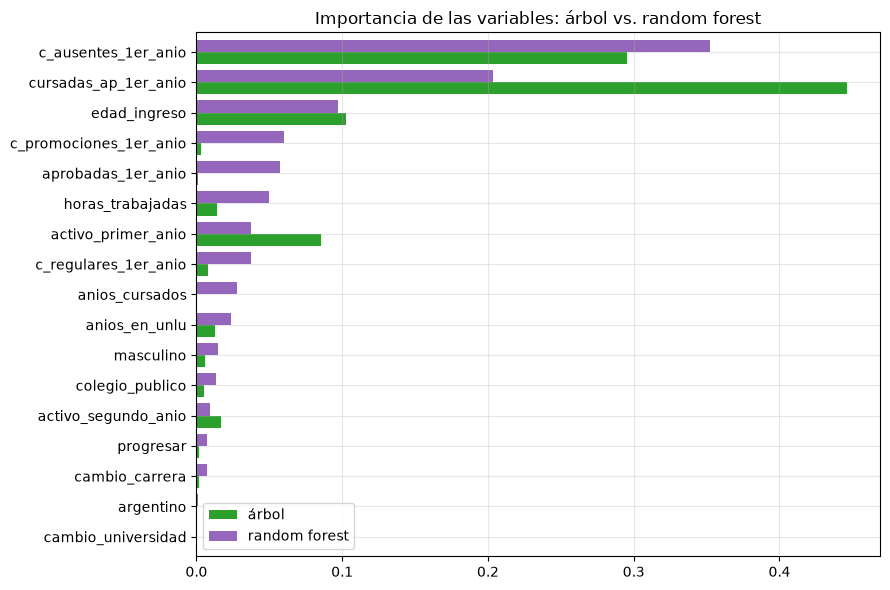

In [35]:
imp = pd.DataFrame({
    "árbol": imp_arbol,
    "random forest": pd.Series(gs_rf.best_estimator_[-1].feature_importances_, index=VARIABLES),
}).sort_values("random forest")

imp.plot.barh(figsize=(9, 6), width=0.8, color=["tab:green", "tab:purple"])
plt.title("Importancia de las variables: árbol vs. random forest")
plt.tight_layout()
plt.show()

El árbol concentra la importancia en pocas variables: las que eligió en los primeros
cortes. El bosque la reparte más, porque al sortear variables en cada nodo les da
oportunidad también a las que el árbol individual "tapaba".

---

## 8. Comparación de los modelos con validación cruzada

Ya tenemos tres modelos ajustados, cada uno con sus mejores hiperparámetros, más la línea
base. Para compararlos en igualdad de condiciones los evaluamos con **los mismos folds**
(`CV5`) y las mismas métricas.

> Hay un detalle fino: el F1 de CV que reportó cada `GridSearchCV` es un poco **optimista**,
> porque elegimos la mejor de muchas combinaciones mirando esos mismos folds. La forma
> rigurosa de evitarlo es la *validación cruzada anidada*. Para comparar modelos entre sí
> alcanza con esto, y el test de la sección 10 da la estimación honesta.

In [36]:
modelos = {
    "dummy": DummyClassifier(strategy="most_frequent"),
    "árbol": gs_arbol.best_estimator_,
    "logística": gs_logistica.best_estimator_,
    "random forest": gs_rf.best_estimator_,
}

por_fold = []
for nombre, modelo in modelos.items():
    r = cross_validate(modelo, X_train, y_train, cv=CV5, scoring=METRICAS, n_jobs=-1)
    for k in range(5):
        por_fold.append({"modelo": nombre, "fold": k + 1,
                         **{m: r[f"test_{m}"][k] for m in METRICAS}})
por_fold = pd.DataFrame(por_fold)

resumen_cv = por_fold.groupby("modelo", sort=False)[list(METRICAS)].agg(["mean", "std"])
resumen_cv.style.format("{:.3f}").background_gradient(
    cmap="Greens", subset=[(m, "mean") for m in METRICAS])

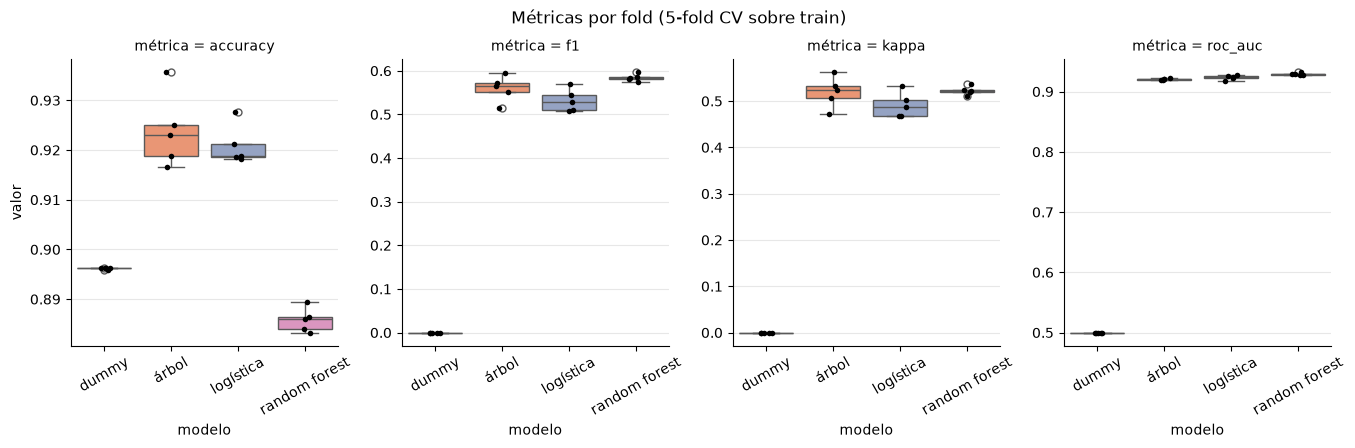

In [37]:
largo = por_fold.melt(id_vars=["modelo", "fold"], value_vars=["accuracy", "f1", "kappa", "roc_auc"],
                      var_name="métrica", value_name="valor")

g = sns.catplot(largo, x="modelo", y="valor", col="métrica", kind="box", sharey=False,
                height=3.8, aspect=0.9, palette="Set2", hue="modelo", legend=False)
g.map_dataframe(sns.stripplot, x="modelo", y="valor", color="black", size=4)
g.set_xticklabels(rotation=30)
g.fig.suptitle("Métricas por fold (5-fold CV sobre train)", y=1.04)
plt.show()

Lo que hay que leer en el gráfico:

- En **accuracy** todos los modelos, incluido el dummy, quedan en una franja de unos pocos
  puntos. Es la métrica que menos discrimina.
- En **F1** y **kappa** el dummy queda en 0 y aparecen las diferencias reales entre modelos.
- Si el random forest ganador usa `class_weight="balanced_subsample"`, su **accuracy puede
  quedar por debajo del dummy** y aun así ser el mejor modelo: marca más positivos, se
  equivoca más veces en total, pero detecta muchos más alumnos en riesgo.
- La **dispersión** entre folds importa tanto como la media: si las cajas de dos modelos se
  superponen mucho, la diferencia entre ellos puede no ser significativa.

---

## 9. Umbral de decisión

Todos los modelos usaron el umbral por defecto de 0,5 sobre la probabilidad. Pero con clases
desbalanceadas 0,5 casi nunca es el mejor umbral para F1. Como el umbral **también es una
decisión del modelo**, lo elegimos igual que los hiperparámetros: **con predicciones de CV
sobre train**, nunca mirando el test.

Lo hacemos para el modelo con mejor F1 en la comparación anterior.

Mejor modelo por F1 de CV: random forest


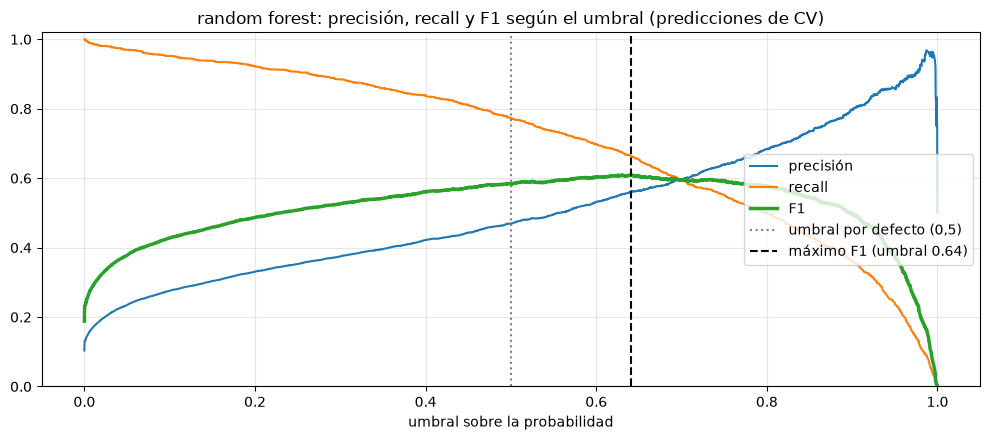

F1 CV con umbral 0,5  : 0.584
F1 CV con umbral 0.64 : 0.609


In [38]:
nombre_mejor = resumen_cv[("f1", "mean")].drop("dummy").idxmax()
modelo_mejor = modelos[nombre_mejor]
print("Mejor modelo por F1 de CV:", nombre_mejor)

proba_cv = cross_val_predict(modelo_mejor, X_train, y_train, cv=CV5, method="predict_proba", n_jobs=-1)[:, 1]
prec_u, rec_u, umbrales = precision_recall_curve(y_train, proba_cv)
f1_u = 2 * prec_u[:-1] * rec_u[:-1] / np.clip(prec_u[:-1] + rec_u[:-1], 1e-12, None)

UMBRAL = float(umbrales[np.argmax(f1_u)])

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(umbrales, prec_u[:-1], label="precisión")
ax.plot(umbrales, rec_u[:-1], label="recall")
ax.plot(umbrales, f1_u, label="F1", lw=2.5)
ax.axvline(0.5, color="gray", ls=":", label="umbral por defecto (0,5)")
ax.axvline(UMBRAL, color="black", ls="--", label=f"máximo F1 (umbral {UMBRAL:.2f})")
ax.set_xlabel("umbral sobre la probabilidad"); ax.set_ylim(0, 1.02); ax.legend(loc="center right")
ax.set_title(f"{nombre_mejor}: precisión, recall y F1 según el umbral (predicciones de CV)")
plt.tight_layout()
plt.show()

print(f"F1 CV con umbral 0,5  : {f1_score(y_train, proba_cv >= 0.5):.3f}")
print(f"F1 CV con umbral {UMBRAL:.2f} : {f1_score(y_train, proba_cv >= UMBRAL):.3f}")

Mover el umbral es elegir el punto de operación:

- **Bajarlo** marca más alumnos como positivos: sube el recall y baja la precisión.
- **Subirlo** hace lo contrario.

Si el umbral óptimo quedó **por encima** de 0,5, es porque el modelo se entrenó con
`class_weight` balanceado: los pesos ya empujan las probabilidades de la clase minoritaria
hacia arriba, y el umbral las compensa. Sin pesos, lo habitual es que el óptimo quede por
debajo de 0,5. Las dos estrategias (pesos de clase o umbral) atacan el mismo problema, el
desbalance.

---

## 10. Evaluación final sobre el conjunto de test

Todas las decisiones están tomadas: modelo, hiperparámetros y umbral. Recién ahora usamos el
test, **una sola vez**. Los modelos de `GridSearchCV` ya están reentrenados con todo el
train (`refit`), y al dummy lo entrenamos acá.

In [39]:
modelos["dummy"].fit(X_train, y_train)

def evaluar(y_real, pred, proba):
    return {"accuracy": accuracy_score(y_real, pred),
            "precision": precision_score(y_real, pred, zero_division=0),
            "recall": recall_score(y_real, pred), "f1": f1_score(y_real, pred),
            "kappa": cohen_kappa_score(y_real, pred), "roc_auc": roc_auc_score(y_real, proba)}

probas_test = {n: m.predict_proba(X_test)[:, 1] for n, m in modelos.items()}
preds_test = {n: (p >= 0.5).astype(int) for n, p in probas_test.items()}
preds_test[f"{nombre_mejor} (umbral {UMBRAL:.2f})"] = (probas_test[nombre_mejor] >= UMBRAL).astype(int)
probas_test[f"{nombre_mejor} (umbral {UMBRAL:.2f})"] = probas_test[nombre_mejor]

resultados_test = pd.DataFrame({n: evaluar(y_test, preds_test[n], probas_test[n]) for n in preds_test}).T
resultados_test.style.format("{:.3f}").background_gradient(cmap="Greens")

,accuracy,precision,recall,f1,kappa,roc_auc
dummy,0.896,0.000,0.000,0.000,0.000,0.500
árbol,0.927,0.756,0.440,0.556,0.519,0.928
logística,0.925,0.734,0.431,0.543,0.505,0.929
random forest,0.893,0.491,0.770,0.599,0.541,0.933
random forest (umbral 0.64),0.915,0.577,0.667,0.618,0.571,0.933


### 10.1 Matrices de confusión

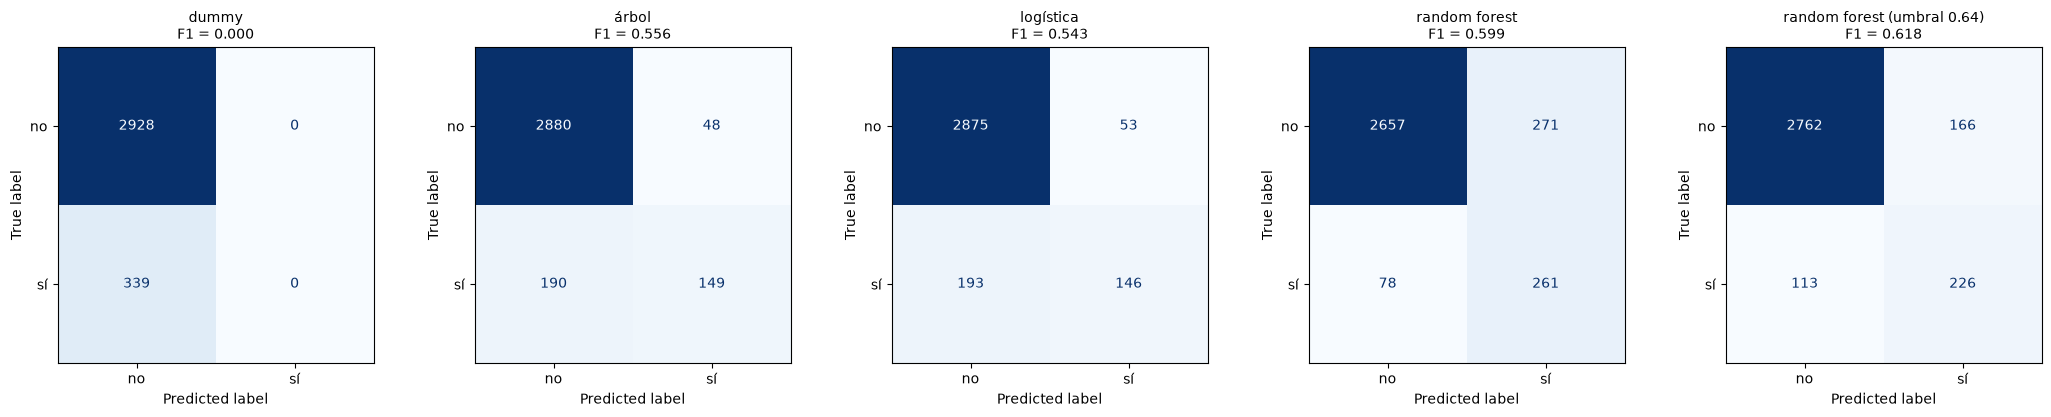

In [40]:
fig, axes = plt.subplots(1, len(preds_test), figsize=(4.2 * len(preds_test), 4))
for ax, (nombre, pred) in zip(axes, preds_test.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["no", "sí"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{nombre}\nF1 = {f1_score(y_test, pred):.3f}", fontsize=10)
    ax.grid(False)
plt.tight_layout()
plt.show()

### 10.2 Curvas ROC y Precisión-Recall en test

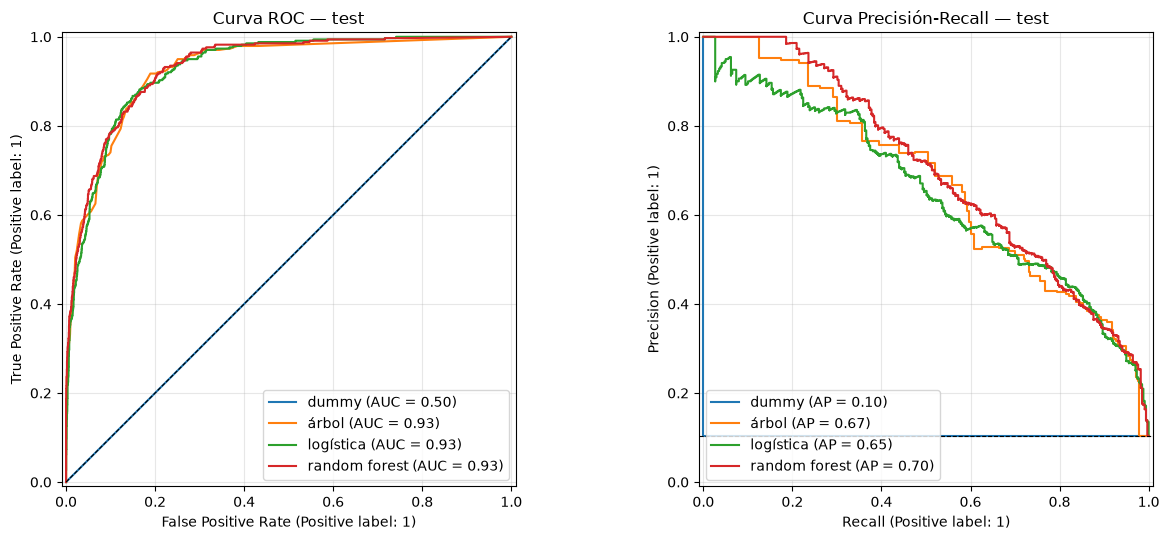

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for nombre in modelos:
    RocCurveDisplay.from_predictions(y_test, probas_test[nombre], name=nombre, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probas_test[nombre], name=nombre, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set_title("Curva ROC — test")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=0.8)
axes[1].set_title("Curva Precisión-Recall — test")
plt.tight_layout()
plt.show()

### 10.3 Reporte del modelo elegido

In [42]:
final = f"{nombre_mejor} (umbral {UMBRAL:.2f})"
print(final, "\n")
print(classification_report(y_test, preds_test[final], target_names=["no fracasa", "fracasa"], digits=3))

comparacion = pd.DataFrame({
    "CV sobre train (umbral 0,5)": resumen_cv.loc[nombre_mejor].xs("mean", level=1),
    "test (umbral 0,5)": resultados_test.loc[nombre_mejor],
}).round(3)
comparacion

random forest (umbral 0.64) 

              precision    recall  f1-score   support

  no fracasa      0.961     0.943     0.952      2928
     fracasa      0.577     0.667     0.618       339

    accuracy                          0.915      3267
   macro avg      0.769     0.805     0.785      3267
weighted avg      0.921     0.915     0.917      3267



,"CV sobre train (umbral 0,5)","test (umbral 0,5)"
accuracy,0.886,0.893
f1,0.584,0.599
kappa,0.523,0.541
precision,0.470,0.491
recall,0.774,0.770
roc_auc,0.929,0.933


La tabla final compara la estimación de CV con el resultado en test. Si los dos números son
parecidos, la validación cruzada hizo su trabajo: estimó bien cómo se iba a comportar el
modelo con datos no vistos. Si el test diera bastante peor, sería señal de que sobreajustamos
la **selección** (probamos demasiadas cosas mirando los mismos folds).

---

## 11. Conclusiones

1. **Entender los datos antes que nada.** La etiqueta estaba definida por una fórmula sobre
   dos columnas. Ninguna métrica lo habría detectado: un F1 de 1,0 parece un éxito.
2. **El test se aparta al principio y se usa una sola vez.** Todas las decisiones (modelo,
   hiperparámetros, umbral) se toman con validación cruzada sobre train.
3. **Con clases desbalanceadas el accuracy engaña.** El modelo trivial saca 90 %. Hay que
   mirar precisión, recall, F1, kappa y la curva PR.
4. **Sesgo–varianza.** La complejidad (profundidad, hojas, `C`, α de poda) se elige donde el
   error de validación es mínimo, no donde el de train es mínimo.
5. **Árbol vs. bosque vs. logística.** El árbol es el más interpretable (se puede dibujar y
   leer como reglas), el random forest suele ser el más preciso, y la logística da
   coeficientes con signo y magnitud. La elección depende de para qué se va a usar el modelo.